In [1]:
import pandas as pd
from pathlib import Path

# load transaction data with optimized dtypes (CSV folder next to this notebook)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data/raw/ieee_cis"
train_transaction = pd.read_csv(DATA_DIR / "train_transaction.csv")
test_transaction = pd.read_csv(DATA_DIR / "test_transaction.csv")


In [2]:
train_identity = pd.read_csv(DATA_DIR / "train_identity.csv")
test_identity = pd.read_csv(DATA_DIR / "test_identity.csv")

In [3]:
import gc

train_df = train_transaction.merge(train_identity, on='TransactionID', how='left')
test_df = test_transaction.merge(test_identity, on='TransactionID', how='left')

del train_transaction, train_identity, test_transaction, test_identity
gc.collect()

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")

Train shape: (590540, 434)
Test shape: (506691, 433)


Exploratory Data Analysis

In [4]:
print("Dataset Shape: ", train_df.shape)


Dataset Shape:  (590540, 434)


In [5]:
print("\nDataset Info: \n", train_df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 434 entries, TransactionID to DeviceInfo
dtypes: float64(399), int64(4), object(31)
memory usage: 1.9+ GB

Dataset Info: 
 None


In [6]:
print("\nMissing Values: \n", train_df.isnull().sum())



Missing Values: 
 TransactionID          0
isFraud                0
TransactionDT          0
TransactionAmt         0
ProductCD              0
                   ...  
id_36             449555
id_37             449555
id_38             449555
DeviceType        449730
DeviceInfo        471874
Length: 434, dtype: int64


In [7]:
print("\nDescriptive Statistics: \n", train_df.describe().T)



Descriptive Statistics: 
                    count          mean           std          min  \
TransactionID   590540.0  3.282270e+06  1.704744e+05  2987000.000   
isFraud         590540.0  3.499001e-02  1.837546e-01        0.000   
TransactionDT   590540.0  7.372311e+06  4.617224e+06    86400.000   
TransactionAmt  590540.0  1.350272e+02  2.391625e+02        0.251   
card1           590540.0  9.898735e+03  4.901170e+03     1000.000   
...                  ...           ...           ...          ...   
id_22             5169.0  1.600271e+01  6.897665e+00       10.000   
id_24             4747.0  1.280093e+01  2.372447e+00       11.000   
id_25             5132.0  3.296089e+02  9.746109e+01      100.000   
id_26             5163.0  1.490703e+02  3.210199e+01      100.000   
id_32            77586.0  2.650860e+01  3.737502e+00        0.000   

                        25%          50%          75%           max  
TransactionID   3134634.750  3282269.500   3429904.25  3.577539e+06  
isFr

In [8]:
print("Dataset Columns: \n", train_df.columns)


Dataset Columns: 
 Index(['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt',
       'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5',
       ...
       'id_31', 'id_32', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38',
       'DeviceType', 'DeviceInfo'],
      dtype='object', length=434)


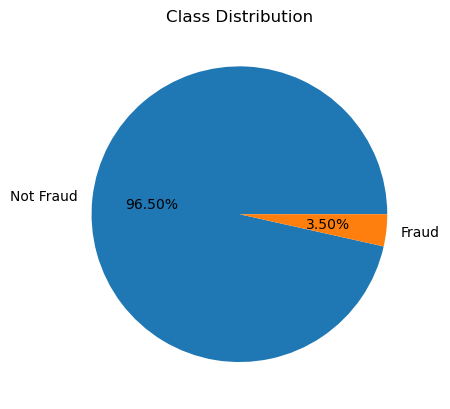

In [9]:
import matplotlib.pyplot as plt

plt.pie(train_df['isFraud'].value_counts(), labels=['Not Fraud', 'Fraud'], autopct='%0.2f%%')
plt.title('Class Distribution')
plt.show()

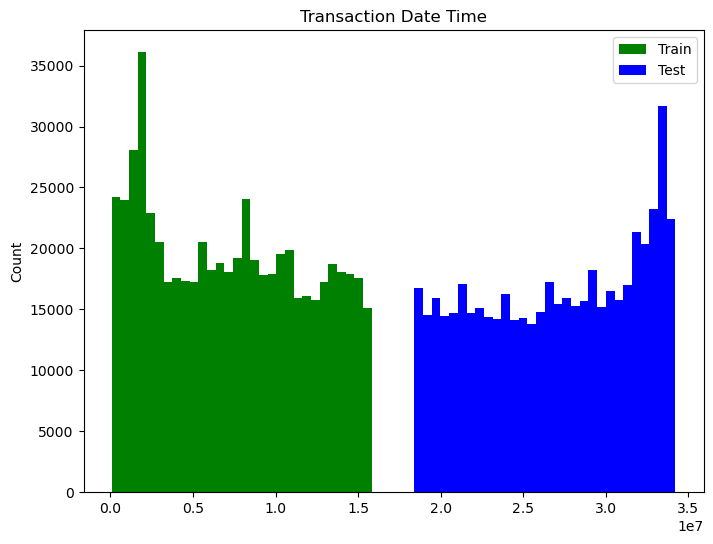

In [10]:
plt.figure(figsize=(8, 6))
plt.hist(train_df['TransactionDT'], label='Train', bins = 30, color='green')
plt.hist(test_df['TransactionDT'], label='Test', bins = 30, color= 'blue')
plt.ylabel('Count')
plt.title('Transaction Date Time')
plt.legend()
plt.show()

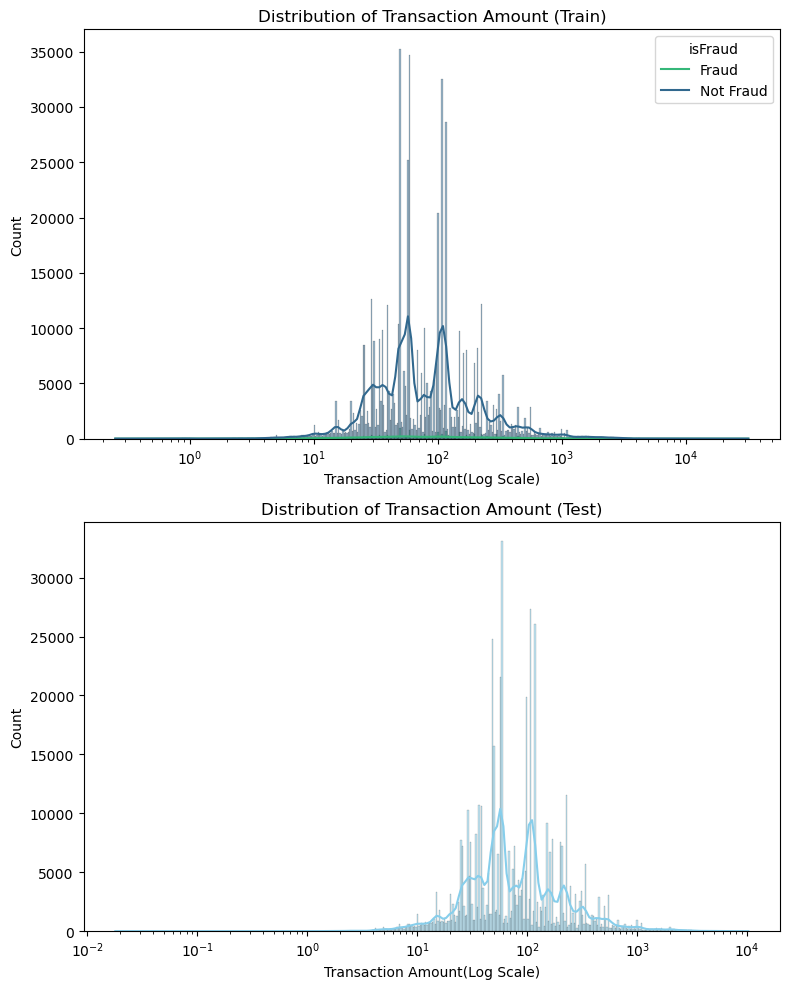

In [11]:
import seaborn as sns

fig, ax = plt.subplots(2, 1, figsize=(8, 10))

sns.histplot(data=train_df, x='TransactionAmt', hue='isFraud', kde=True, palette='viridis',log_scale=True , ax=ax[0])
ax[0].set(title='Distribution of Transaction Amount (Train)', xlabel='Transaction Amount(Log Scale)', ylabel='Count')
ax[0].legend(title='isFraud', labels=['Fraud', 'Not Fraud'])

sns.histplot(data=test_df, x='TransactionAmt', kde=True,log_scale=True , color='skyblue', ax=ax[1])
ax[1].set(title='Distribution of Transaction Amount (Test)', xlabel='Transaction Amount(Log Scale)', ylabel='Count')

plt.tight_layout()
plt.show()

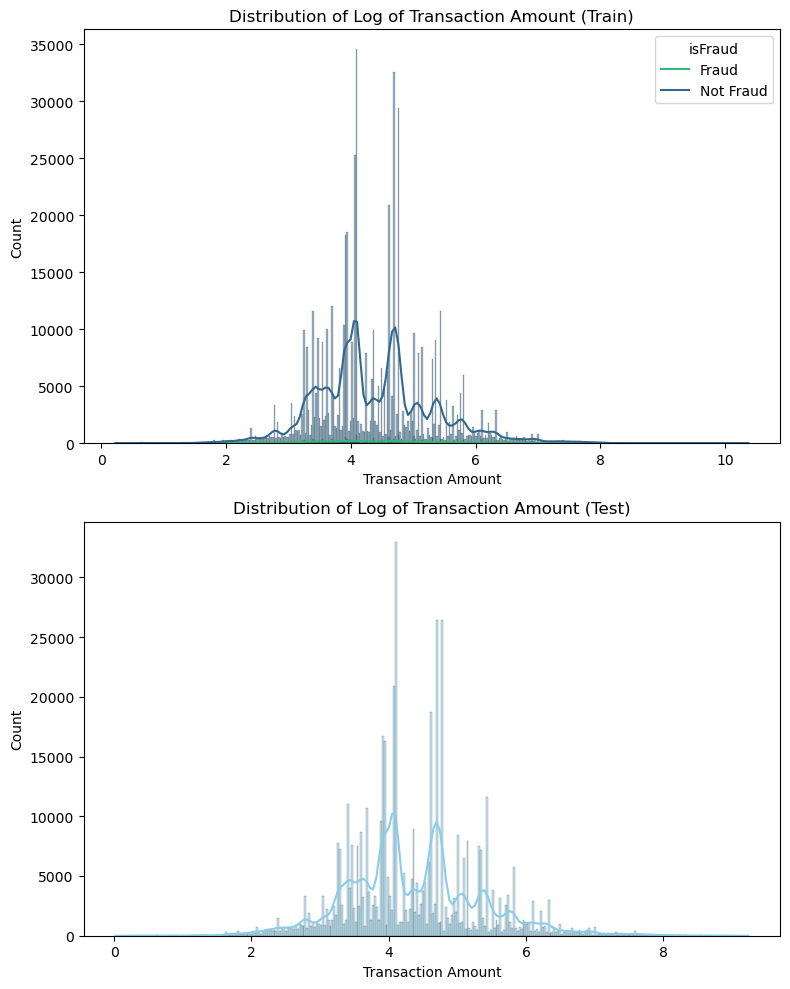

In [12]:
import numpy as np

fig, ax = plt.subplots(2, 1, figsize=(8, 10))

train_df['TransactionAmt_log'] = np.log1p(train_df['TransactionAmt'])
sns.histplot(data=train_df, x='TransactionAmt_log', hue='isFraud', kde=True, palette='viridis', ax=ax[0])
ax[0].set(title='Distribution of Log of Transaction Amount (Train)', xlabel='Transaction Amount', ylabel='Count')
ax[0].legend(title='isFraud', labels=['Fraud', 'Not Fraud'])

test_df['TransactionAmt_log'] = np.log1p(test_df['TransactionAmt'])
sns.histplot(data=test_df, x='TransactionAmt_log', kde=True, color='skyblue', ax=ax[1])
ax[1].set(title='Distribution of Log of Transaction Amount (Test)', xlabel='Transaction Amount', ylabel='Count')

plt.tight_layout()
plt.show()

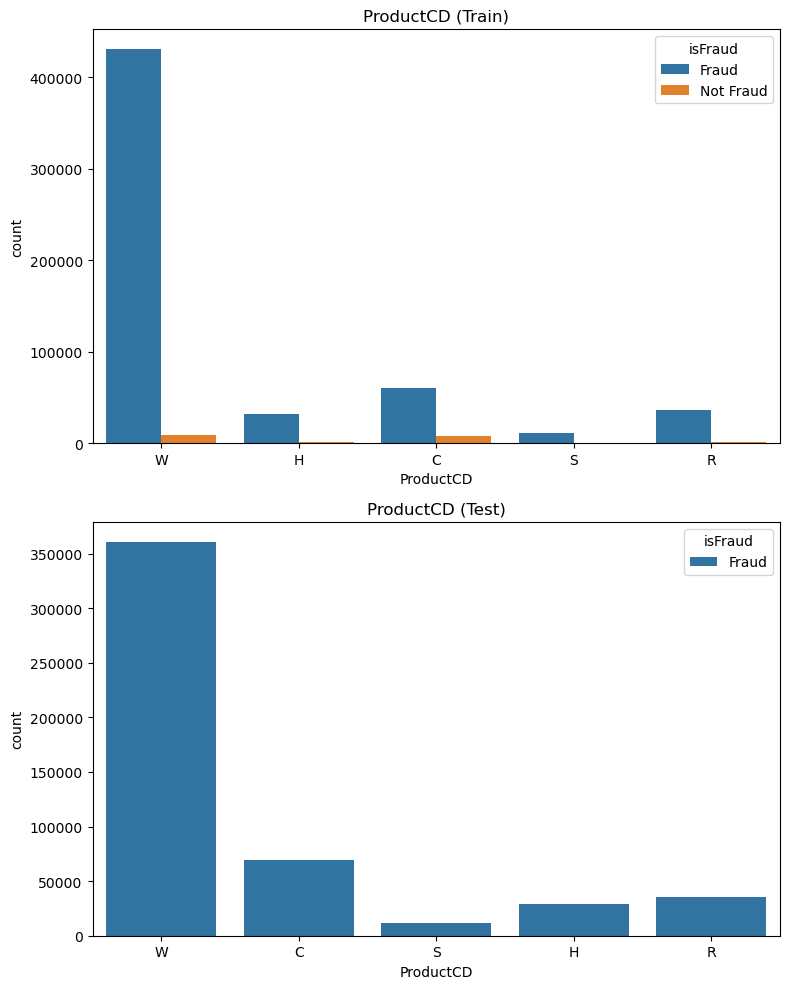

In [13]:
fig, ax = plt.subplots(2, 1, figsize=(8, 10))

sns.countplot(data=train_df, x="ProductCD", ax=ax[0], hue = "isFraud")
ax[0].set_title('ProductCD (Train)')
ax[0].legend(title='isFraud', labels=['Fraud', 'Not Fraud'])

sns.countplot(data=test_df, x="ProductCD", ax=ax[1])
ax[1].set_title('ProductCD (Test)')
ax[1].legend(title='isFraud', labels=['Fraud', 'Not Fraud'])

plt.tight_layout()
plt.show()

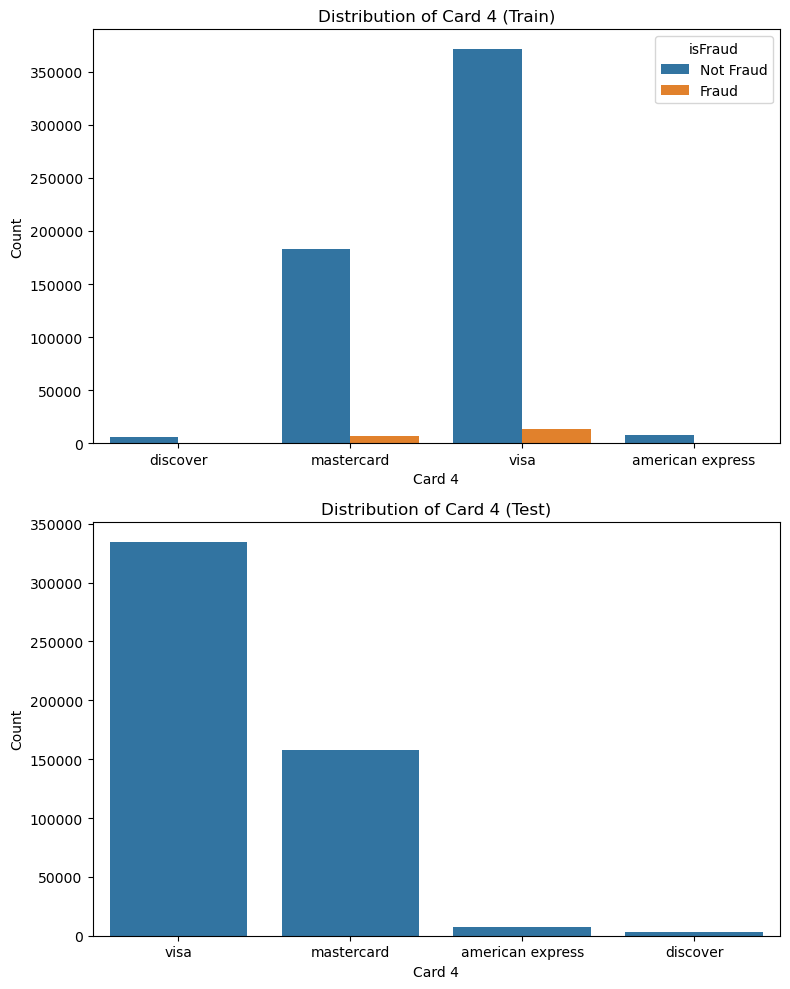

In [14]:
fig, ax = plt.subplots(2, 1, figsize=(8, 10))

sns.countplot(data=train_df, x='card4', hue='isFraud', ax=ax[0])
ax[0].set_title('Distribution of Card 4 (Train)')
ax[0].set_xlabel('Card 4')
ax[0].set_ylabel('Count')
ax[0].legend(title='isFraud', labels=['Not Fraud', 'Fraud'])

sns.countplot(data=test_df, x='card4', ax=ax[1])
ax[1].set_title('Distribution of Card 4 (Test)')
ax[1].set_xlabel('Card 4')
ax[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

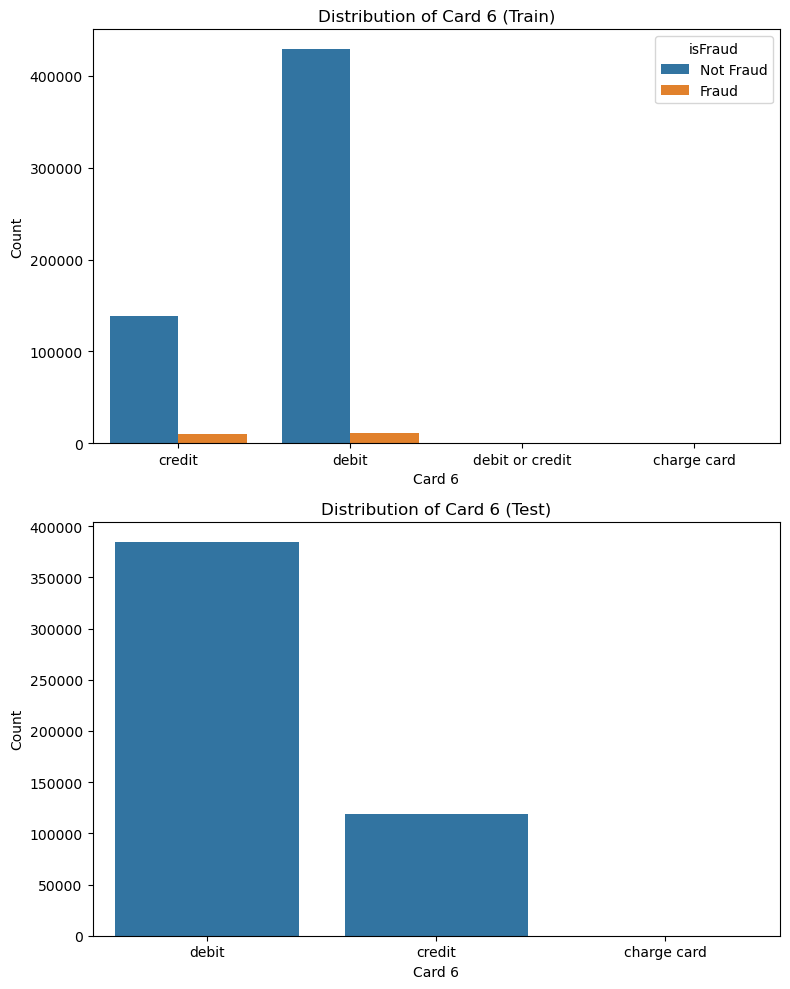

In [15]:
fig, ax = plt.subplots(2, 1, figsize=(8, 10))


sns.countplot(data=train_df, x='card6', hue='isFraud', ax=ax[0])
ax[0].set_title('Distribution of Card 6 (Train)')
ax[0].set_xlabel('Card 6')
ax[0].set_ylabel('Count')
ax[0].legend(title='isFraud', labels=['Not Fraud', 'Fraud'])

sns.countplot(data=test_df, x='card6', ax=ax[1])
ax[1].set_title('Distribution of Card 6 (Test)')
ax[1].set_xlabel('Card 6')
ax[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

Feature Engineering

In [16]:
def engineer_features_optimized(df):
    """Memory efficient feature engineering"""
    
    # create unique ID for aggregations
    df['uid'] = df['card1'].astype(str) + '_' + df['card2'].fillna(0).astype(str)
    
    # transaction amount features
    df['TransactionAmt_log'] = np.log1p(df['TransactionAmt'])
    df['TransactionAmt_decimal'] = (df['TransactionAmt'] - df['TransactionAmt'].astype(int))
    
    # time-based features
    df['TransactionDT_day'] = (df['TransactionDT'] // (24*3600)).astype(np.int16)
    df['TransactionDT_hour'] = ((df['TransactionDT'] % (24*3600)) // 3600).astype(np.int8)
    
    # aggregation features (memory-efficient)
    for agg_col in ['TransactionAmt']:
        for stat in ['mean', 'std']:
            col_name = f'uid_{agg_col.lower()}_{stat}'
            df[col_name] = df.groupby('uid')[agg_col].transform(stat)
            df[col_name] = df[col_name].astype(np.float32)
    
    # transaction amount deviation
    df['TransactionAmt_deviation'] = df['TransactionAmt'] / (df['uid_transactionamt_mean'] + 1e-5)
    df['TransactionAmt_deviation'] = df['TransactionAmt_deviation'].astype(np.float32)
    
    # frequency encoding for top features
    for col in ['card1', 'card2', 'addr1']:
        freq = df[col].value_counts(dropna=False)
        df[f'{col}_freq'] = df[col].map(freq).astype(np.float32)
    
    # browser extraction from id_31
    if 'id_31' in df.columns:
        df['browser'] = df['id_31'].astype(str).str.extract('([a-zA-Z]+)', expand=False).fillna('unknown')
        df['browser'] = df['browser'].astype('category')
    
    # drop temporary columns
    df.drop(['uid'], axis=1, inplace=True)
    
    return df


In [17]:
# apply feature engineering
train_df = engineer_features_optimized(train_df)
test_df = engineer_features_optimized(test_df)

gc.collect()
print(f"Train shape after feature engineering: {train_df.shape}")
print(f"Test shape after feature engineering: {test_df.shape}")

Train shape after feature engineering: (590540, 445)
Test shape after feature engineering: (506691, 443)


Data Cleaning


In [18]:
# remove duplicates
print(f"Train shape before dropping duplicates: {train_df.shape}")
train_df.drop_duplicates(inplace=True)
print(f"Train shape after dropping duplicates: {train_df.shape}")

print(f"Test shape before dropping duplicates: {test_df.shape}")
test_df.drop_duplicates(inplace=True)
print(f"Test shape after dropping duplicates: {test_df.shape}")

Train shape before dropping duplicates: (590540, 445)


Train shape after dropping duplicates: (590540, 445)
Test shape before dropping duplicates: (506691, 443)


Test shape after dropping duplicates: (506691, 443)


In [19]:
# drop columns with >80% missing values
threshold = 0.8

print(f"Train shape before dropping columns: {train_df.shape}")
train_missing = train_df.isnull().sum() / len(train_df)
cols_to_drop = train_missing[train_missing > threshold].index.tolist()
train_df.drop(columns=cols_to_drop, inplace=True)
print(f"Dropped {len(cols_to_drop)} columns with >{threshold*100}% missing")
print(f"Train shape after: {train_df.shape}")

print(f"Test shape before: {test_df.shape}")
test_missing = test_df.isnull().sum() / len(test_df)
cols_to_drop_test = test_missing[test_missing > threshold].index.tolist()
test_df.drop(columns=cols_to_drop_test, inplace=True)
print(f"Dropped {len(cols_to_drop_test)} columns with >{threshold*100}% missing")
print(f"Test shape after: {test_df.shape}")

Train shape before dropping columns: (590540, 445)


Dropped 74 columns with >80.0% missing
Train shape after: (590540, 371)
Test shape before: (506691, 443)


Dropped 71 columns with >80.0% missing
Test shape after: (506691, 372)


Prepare Data for Modeling

In [20]:
target = 'isFraud'
y = train_df[target]
X_train = train_df.drop(columns=[target, 'TransactionID'])
X_test = test_df.drop(columns=['TransactionID'])

print(f"Features shape: {X_train.shape}")
print(f"Target distribution:\n{y.value_counts()}")
print(f"Fraud rate: {y.mean()*100:.2f}%")

Features shape: (590540, 369)
Target distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64
Fraud rate: 3.50%


In [21]:
from sklearn.preprocessing import OrdinalEncoder
import gc

# identify categorical columns
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
test_cat_cols = X_test.select_dtypes(include=['object', 'category']).columns.tolist()

# find common columns
common_cat_cols = list(set(cat_cols) & set(test_cat_cols))
print(f"Encoding {len(common_cat_cols)} categorical columns")

# initialise ordinal encoder
oe = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

# handle missing values and encode
X_train[common_cat_cols] = X_train[common_cat_cols].astype(str)
X_test[common_cat_cols] = X_test[common_cat_cols].astype(str)

# apply encoding
X_train[common_cat_cols] = oe.fit_transform(X_train[common_cat_cols])
X_test[common_cat_cols] = oe.transform(X_test[common_cat_cols])

# optimize memory
num_cols = X_train.select_dtypes(include=['float64']).columns
for col in num_cols:
    X_train[col] = X_train[col].astype('float32')
    if col in X_test.columns:
        X_test[col] = X_test[col].astype('float32')

print(f"Final feature count: {X_train.shape[1]}")

# identify leftover object columns
non_numeric_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

# drop columns
print(f"Dropping {len(non_numeric_cols)} unencoded columns")
X_train = X_train.drop(columns=non_numeric_cols)
X_test = X_test.drop(columns=non_numeric_cols, errors='ignore')

# reindex adds missing columns to test and fills them with 0
X = X_train
X_test = X_test.reindex(columns=X.columns, fill_value=0)

# free memory
gc.collect()

Encoding 16 categorical columns


Final feature count: 369
Dropping 11 unencoded columns


162721

Model Training with Cross Validation

In [22]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(X_tr.shape, X_val.shape)

(472432, 358) (118108, 358)


In [23]:
import sys
import subprocess

# Ensure xgboost exists in the currently running notebook environment
try:
    from xgboost import XGBClassifier
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost"])
    from xgboost import XGBClassifier

scale = (y_tr == 0).sum() / (y_tr == 1).sum()

# Use GPU when available; fallback to CPU if CUDA runtime is unavailable
try:
    model = XGBClassifier(
        n_estimators=400,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale,
        objective="binary:logistic",
        eval_metric="auc",
        tree_method="hist",
        device="cuda",
        random_state=42,
    )
    model.fit(
        X_tr,
        y_tr,
        eval_set=[(X_val, y_val)],
        verbose=50,
    )
except Exception:
    model = XGBClassifier(
        n_estimators=400,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale,
        objective="binary:logistic",
        eval_metric="auc",
        tree_method="hist",
        device="cpu",
        random_state=42,
    )
    model.fit(
        X_tr,
        y_tr,
        eval_set=[(X_val, y_val)],
        verbose=50,
    )

[0]	validation_0-auc:0.85596


/opt/anaconda3/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [19:51:01] WARNING: /Users/runner/work/xgboost/xgboost/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


[50]	validation_0-auc:0.91790


[100]	validation_0-auc:0.93275


[150]	validation_0-auc:0.94347


[200]	validation_0-auc:0.95023


[250]	validation_0-auc:0.95468


[300]	validation_0-auc:0.95869


[350]	validation_0-auc:0.96117


[399]	validation_0-auc:0.96299


In [24]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

y_pred = model.predict(X_val)
y_prob = model.predict_proba(X_val)[:, 1]

print("ROC AUC:", roc_auc_score(y_val, y_prob))
print(confusion_matrix(y_val, y_pred))
print(classification_report(y_val, y_pred))

ROC AUC: 0.9629928755690573
[[109035   4940]
 [   698   3435]]
              precision    recall  f1-score   support

           0       0.99      0.96      0.97    113975
           1       0.41      0.83      0.55      4133

    accuracy                           0.95    118108
   macro avg       0.70      0.89      0.76    118108
weighted avg       0.97      0.95      0.96    118108



<Figure size 1000x800 with 0 Axes>

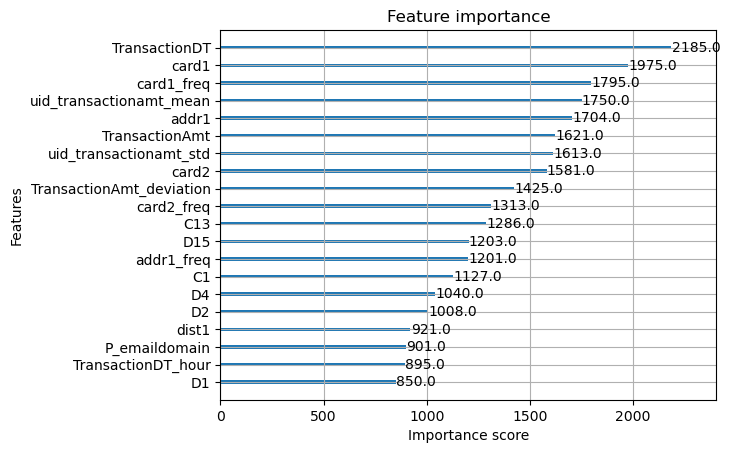

In [25]:
import matplotlib.pyplot as plt
from xgboost import plot_importance

plt.figure(figsize=(10,8))
plot_importance(model, max_num_features=20)
plt.show()

In [26]:
# Dashboard linkage: export validation predictions for src/dashboard/dashboard_app.py
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ARTIFACT_DIR = PROJECT_ROOT / "artifacts/dashboard"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

val_export = pd.DataFrame({
    "y_true": y_val.values if hasattr(y_val, "values") else y_val,
    "y_pred": y_pred,
    "risk_score": y_prob,
})

# X_val.index is the row label in the training matrix, not the business TransactionID.
# Align with the same rows in train_df so the dashboard can merge on TransactionID.
val_export["TransactionID"] = train_df.loc[X_val.index, "TransactionID"].values

feature_output_path = ARTIFACT_DIR / "cleaned_ieee_features.csv"
if "isFraud" in X.columns:
    X.drop(columns=["isFraud"], inplace=True)
X["isFraud"] = y.loc[X.index].values if hasattr(y, "loc") else y
X.to_csv(feature_output_path, index=False)
X.drop(columns=["isFraud"], inplace=True)
print("Saved:", feature_output_path)

output_path = ARTIFACT_DIR / "ieee_cis_val_predictions.csv"
val_export.to_csv(output_path, index=False)
print("Saved:", output_path)

# Run dashboard from terminal:
# streamlit run src/dashboard/dashboard_app.py


/var/folders/50/yl8f1tq165g0xtny_ml7_1380000gn/T/ipykernel_13400/4120135872.py:22: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X["isFraud"] = y.loc[X.index].values if hasattr(y, "loc") else y


Saved: /Users/youseftahoon/DEPI Project/artifacts/dashboard/cleaned_ieee_features.csv
Saved: /Users/youseftahoon/DEPI Project/artifacts/dashboard/ieee_cis_val_predictions.csv
